# 9. EP search for a pulsar in a 20-minute circular orbit

The hardest case: the orbital period (1200 s) is close to the
observation length (1074 s), so acceleration, jerk and the higher
derivatives all matter. A Taylor polynomial of order 5 (frequency up to
crackle, the fifth phase derivative) is enough over the observation;
the EP search prunes over all five parameters.

The parameter ranges come from the orbits to cover rather than from
guessed derivative limits: every circular orbit with period at least
`p_orb_min`, companion mass at most `m_c_max` and pulsar mass at least
`m_p_min` (`libloki.configs.circular_param_limits`). The same orbit
limits go into the search configuration, which uses them to bound the
higher derivatives during pruning.

Runtime: about 7 minutes; memory: about 11 GB (4 threads).

In [1]:
%matplotlib inline
import shutil
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt

from loki import libloki
from loki.libloki.configs import PulsarSearchConfig, circular_param_limits
from loki.libloki.plans import FFAPlanBase
from loki.libloki.prune import EPMultiPassFourier
from pyloki.periodogram import PruningStatsPlotter, ScatteredPeriodogram
from pyloki.simulation.pulse import PulseSignalConfig

libloki.set_log_level("warning")  # hide loki's per-run info messages
SEED = 1
NTHREADS = 4  # CPU threads; raise it on a machine of your own
OUTDIR = Path("_output/09_ep_circular")
shutil.rmtree(OUTDIR, ignore_errors=True)  # EP refuses to overwrite earlier runs

## Simulated data

A 7 ms pulsar in a circular orbit of period 1200 s with an 8 M☉
companion, folded S/N 11.5, in 2^24 samples of 64 µs. The first fold uses
the exact orbit; the second uses its Taylor expansion (15 terms) about
the middle of the observation, the model the search approximates.

T_obs = 1073.7 s, spin frequency = 142.857143 Hz


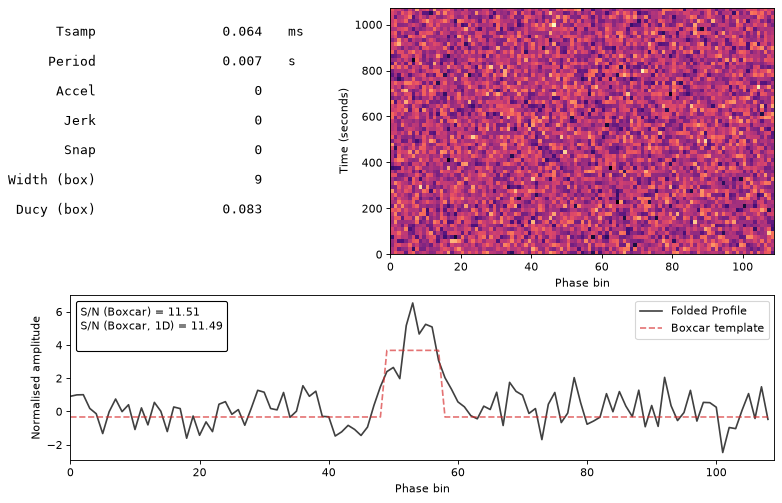

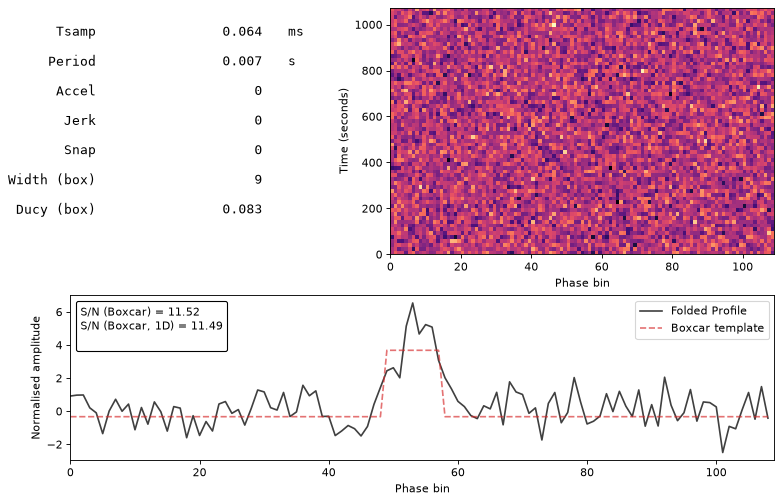

In [2]:
orbit = {"p_orb": 1200.0, "psi": np.pi / 4.1, "m_c": 8.0}
cfg = PulseSignalConfig(
    period=0.007,
    dt=64e-6,
    nsamps=2**24,
    snr=11.5,
    ducy=0.1,
    mod_kwargs=orbit,
    mod_type="circular",
    seed=SEED,
)
tim_data = cfg.generate(shape="gaussian")
print(f"T_obs = {cfg.tobs:.1f} s, spin frequency = {cfg.freq:.6f} Hz")
tim_data.plot_fold(
    cfg.freq,
    cfg.fold_bins,
    mod_kwargs=orbit,
    mod_type="circular",
    dpi=80,
)
plt.show()
tim_data.plot_fold(
    cfg.freq,
    cfg.fold_bins,
    mod_kwargs=cfg.mod_func.to_derivatives_series(n=15),
    mod_type="derivative_series",
    dpi=80,
)
plt.show()

The true search parameters are the derivatives of the apparent spin
frequency at the middle of the observation:

In [3]:
truth = cfg.mod_func.to_derivatives_gauge(cfg.freq)
names = ["crackle", "snap", "jerk", "accel", "freq"]
true_values = {name: truth["acc" if name == "accel" else name] for name in names}
for name, value in true_values.items():
    print(f"{name:>8}: {value:.6g}")

 crackle: 0.000865409
    snap: 0.159067
    jerk: -31.5663
   accel: -5802.06
    freq: 142.311


## Search configuration and thresholds

Orbits with `P_orb ≥ T_obs`, `m_c ≤ 10 M☉`, `m_p ≥ 1.2 M☉`, spin
frequency 142.5–143.5 Hz.

The schedule is designed for loki's default `target_snr` for five
parameters, 10, below the injected 11.5. The design
simulates a pulse folded without loss, but a 5th-order polynomial only
approximates an orbit this short, so the pulsar's S/N in the search
model is lower than injected. Designing for the injected S/N would set
the thresholds too high for the signal the search actually sees.

In [4]:
p_orb_min, m_c_max, m_p_min = cfg.tobs, 10.0, 1.2
limits = circular_param_limits(
    142.5,
    143.5,
    poly_order=5,
    p_orb_min=p_orb_min,
    m_c_max=m_c_max,
    m_p_min=m_p_min,
)
for name, (lo, hi) in zip(names, limits, strict=True):
    print(f"{name:>8}: [{lo:.6g}, {hi:.6g}]")

search_cfg = PulsarSearchConfig(
    nsamps=cfg.nsamps,
    tsamp=cfg.dt,
    nbins=64,
    eta=1,
    param_limits=limits,
    bseg_brute=cfg.nsamps // 8192,
    nsegments=128,
    prune_poly_order=5,
    nthreads=NTHREADS,
    ducy_max=0.5,
    wtsp=1.2,
    use_fourier=True,
    p_orb_min=p_orb_min,
    m_c_max=m_c_max,
    m_p_min=m_p_min,
)
plan = FFAPlanBase(search_cfg)
branching_pattern = np.asarray(plan.get_branching_pattern(), dtype=np.float32)
n_trees = plan.ncoords[-1]

target_snr, ref_ducy = search_cfg.target_snr, 0.1
dts = libloki.thresholds.DynamicThresholdScheme(
    branching_pattern,
    ref_ducy,
    search_cfg.nbins,
    snr_final=target_snr,
    ducy_max=search_cfg.ducy_max,
    wtsp=search_cfg.wtsp,
    mode="improved",
    beam_width=2.0,
    nthreads=NTHREADS,
    seed=SEED,
)
dts.run(thres_neigh=10, show_progress=False)
thresholds = np.asarray(dts.get_best_path_thresholds(min_pd=0.1), dtype=np.float32)
expected = libloki.thresholds.evaluate_scheme(
    thresholds,
    branching_pattern,
    ref_ducy,
    search_cfg.nbins,
    ntrials=2**14,
    snr_final=target_snr,
    ducy_max=search_cfg.ducy_max,
    wtsp=search_cfg.wtsp,
    seed=SEED + 1,  # fresh trials, not the threshold search's
)
print(
    f"{len(branching_pattern)} stages, {n_trees} trees; "
    f"P_d per run = {expected['success_h1_cumul'][-1]:.3f} (on fresh trials)",
)

 crackle: [-0.00215297, 0.00215297]
    snap: [-0.367924, 0.367924]
    jerk: [-62.8751, 62.8751]
   accel: [-10744.8, 10744.8]
    freq: [141.627, 144.379]


127 stages, 2217 trees; P_d per run = 0.082 (on fresh trials)


The branching pattern (mean number of children per node at each stage)
and the number of leaves the schedule expects to survive in all trees
together, against the `max_sugg` cap of a run.

[4.   9.   1.   2.19 4.11 3.   2.74 3.28 1.   1.   3.   1.   1.   2.19 2.05
 3.   1.   3.   1.   3.   1.   1.   2.74 1.09 2.35 3.84 1.   1.   1.   1.
 1.   1.   1.   7.94 1.13 1.   1.   1.   1.   1.   1.   1.   1.   2.19 2.85
 1.44 1.   1.   3.   1.   1.   1.   1.   3.   1.   1.   1.   1.   1.   3.
 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   2.74 1.09 1.   1.   1.
 1.   2.35 1.28 3.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.
 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   3.   2.65 1.13
 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.
 1.   1.   1.   1.   1.   1.   1.  ]


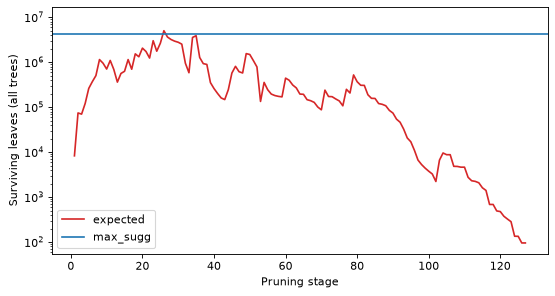

In [5]:
max_sugg = 2**22
print(np.array2string(branching_pattern, precision=2, max_line_width=78))

stages = np.arange(1, len(branching_pattern) + 1)
fig, ax = plt.subplots(figsize=(8, 4), dpi=80)
ax.semilogy(stages, expected["complexity"] * n_trees, c="tab:red", label="expected")
ax.axhline(max_sugg, c="tab:blue", label="max_sugg")
ax.set_xlabel("Pruning stage")
ax.set_ylabel("Surviving leaves (all trees)")
ax.set_ylim(None, 4 * max_sugg)
ax.legend()
plt.show()

## Run the search

16 independent runs. Designing for S/N 10 keeps more noise nodes, and in
some stages the tree of a run reaches `max_sugg`; loki then keeps the
highest-scoring leaves (logged at debug level). With more memory, a
larger `max_sugg` avoids the trimming.

In [6]:
ep = EPMultiPassFourier(
    search_cfg,
    thresholds,
    n_runs=16,
    max_sugg=max_sugg,
    batch_size=1024,
    poly_basis="taylor",
    show_progress=False,
)
ep.execute(tim_data.ts_e, tim_data.ts_v, outdir=str(OUTDIR), file_prefix="circular")
result_file = next(OUTDIR.glob("circular_*_results.h5"))

## Candidates

In [7]:
pgram = ScatteredPeriodogram.load(str(result_file))
print(pgram.get_summary_cands(10, score_type="score", run_id=None))

leaves = pgram.data
near = (abs(leaves["accel"] - true_values["accel"]) < 20.0) & (
    abs(leaves["freq"] - true_values["freq"]) < 1e-3
)
print(f"\nruns that kept the pulsar: {leaves.loc[near, 'run_id'].nunique()} of 16")

Top candidates:
dparams: dcrackle: 1.967189026e-06, dsnap: 0.0001120585105, djerk: 0.00638327722, daccel: 0.8181361457, dfreq: 4.596997369e-05
Run: 084_11, S/N (EP): 8.90, S/N: 9.98, crackle: 0.0008627, snap: 0.15848, jerk: -31.5422, accel: -5794.16, freq: 142.310739
Run: 084_11, S/N (EP): 9.76, S/N: 9.82, crackle: 0.0008627, snap: 0.15848, jerk: -31.5422, accel: -5794.16, freq: 142.310693
Run: 084_11, S/N (EP): 8.57, S/N: 9.78, crackle: 0.0008613, snap: 0.15835, jerk: -31.5170, accel: -5794.21, freq: 142.310793
Run: 084_11, S/N (EP): 9.26, S/N: 9.70, crackle: 0.0008619, snap: 0.15843, jerk: -31.5272, accel: -5795.32, freq: 142.310668
Run: 084_11, S/N (EP): 8.92, S/N: 9.68, crackle: 0.0008626, snap: 0.15849, jerk: -31.5363, accel: -5793.99, freq: 142.310789
Run: 084_11, S/N (EP): 8.36, S/N: 9.67, crackle: 0.0008619, snap: 0.15843, jerk: -31.5272, accel: -5795.32, freq: 142.310714
Run: 084_11, S/N (EP): 8.31, S/N: 9.66, crackle: 0.0008618, snap: 0.15844, jerk: -31.5214, accel: -5795.14,

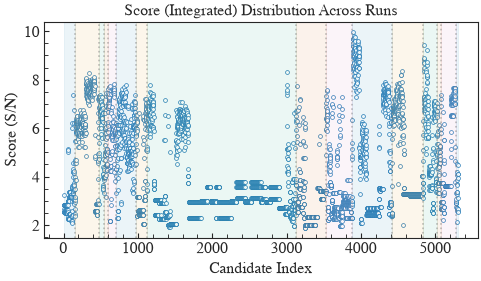

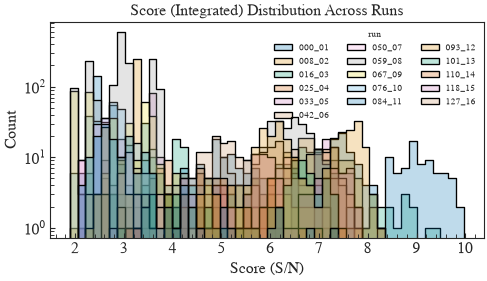

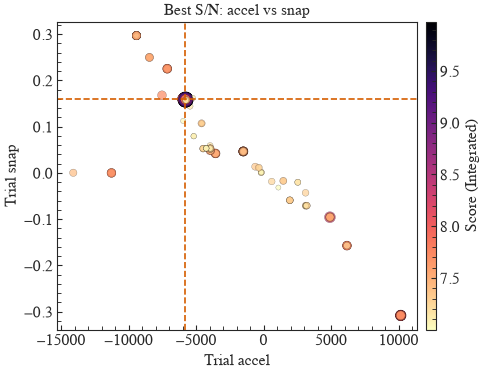

In [8]:
pgram.plot_scores(kind="scatter", run_id=None, dpi=80)
plt.show()
pgram.plot_scores(kind="hist", run_id=None, dpi=80)
plt.show()
pgram.plot_correlation(
    "accel",
    "snap",
    true_values={k: true_values[k] for k in ("accel", "snap")},
    run_id=None,
    snr_min=7,
    figsize=(7, 5),
    dpi=80,
)
plt.show()

## Tree size: expected vs measured

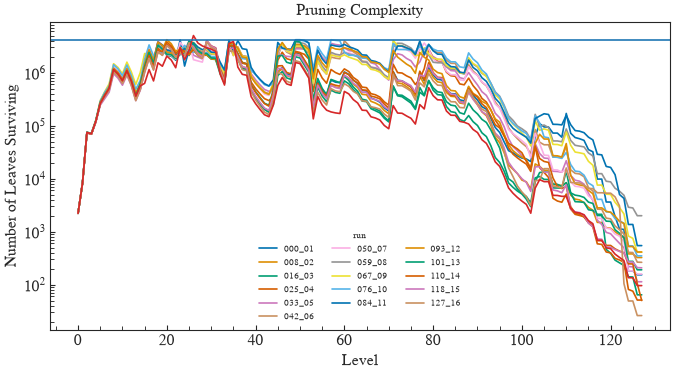

In [9]:
pstats = PruningStatsPlotter.load(str(result_file))
fig = pstats.plot_level_stats(run_id=None, dpi=80)
stages = np.arange(0, len(branching_pattern) + 1)
ax = fig.axes[0]
ax.plot(
    stages,
    np.concatenate(([1], expected["complexity"])) * n_trees,
    c="tab:red",
    label="expected",
)
ax.axhline(max_sugg, c="tab:blue", label="max_sugg")
plt.show()